# TP pratique — Prédiction de séries temporelles

## Comparaison de RNN, LSTM et Transformer

**Objectif :** à partir de 12 observations successives d'une sinusoïde bruitée, prédire l'observation suivante, puis comparer trois réseaux avec les métriques **MSE** et **MAE**.

Le notebook suit les étapes du TP : génération des données, préparation des séquences, définition des architectures, entraînement, évaluation et interprétation des résultats.

> Exécute les cellules dans l'ordre. L'entraînement peut prendre quelques minutes selon l'ordinateur.


## Préparation de l'environnement

Le notebook nécessite Python 3, PyTorch, NumPy et Matplotlib. Si une bibliothèque manque, exécute dans un terminal :

```bash
python -m pip install torch numpy matplotlib ipykernel
```

Dans VS Code, ouvre ce fichier avec l'éditeur **Jupyter Notebook**, puis choisis un kernel Python disposant de ces bibliothèques. `ipykernel` est nécessaire pour que Python apparaisse comme kernel.


In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch : {torch.__version__}')
print(f'Appareil utilisé : {device}')


Matplotlib is building the font cache; this may take a moment.


PyTorch : 2.15.0
Appareil utilisé : cpu


## 1. Génération des données

Chaque exemple est une sinusoïde dont l'amplitude, la fréquence et la phase varient. Un peu de bruit est ajouté. Les 12 premiers points forment l'entrée **X** et le point suivant est la cible **y**.

Les tableaux auront les formes `(nombre_exemples, longueur_sequence, nombre_variables)` pour X et `(nombre_exemples, 1)` pour y, comme attendu par PyTorch.


Forme de X : (2500, 12, 1)
Forme de y : (2500, 1)
Exemple X : [-0.853 -0.24   0.784  0.518 -0.672 -0.817  0.19   1.009  0.251 -0.843
 -0.503  0.603]
Valeur suivante réelle : 0.794


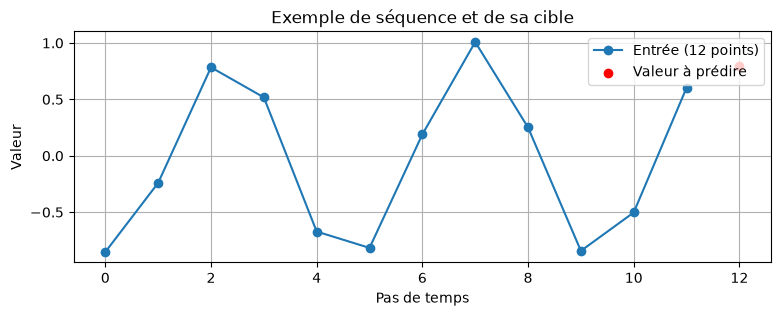

In [2]:
def generate_synthetic_sequences(n_samples=2500, seq_len=12, noise=0.08, seed=SEED):
    rng = np.random.default_rng(seed)
    X = []
    y = []

    for _ in range(n_samples):
        phase = rng.uniform(0, 2 * np.pi)
        amplitude = rng.uniform(0.5, 1.5)
        frequency = rng.uniform(0.3, 1.5)

        time = np.arange(seq_len + 1)
        sequence = amplitude * np.sin(frequency * time + phase)
        sequence += rng.normal(0, noise, size=seq_len + 1)
        X.append(sequence[:-1])
        y.append(sequence[-1])

    X = np.asarray(X, dtype=np.float32).reshape(-1, seq_len, 1)
    y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
    return X, y


X, y = generate_synthetic_sequences()
print(f'Forme de X : {X.shape}')
print(f'Forme de y : {y.shape}')
print('Exemple X :', np.round(X[0, :, 0], 3))
print('Valeur suivante réelle :', round(float(y[0, 0]), 3))

plt.figure(figsize=(9, 3))
plt.plot(np.arange(X.shape[1]), X[0, :, 0], marker='o', label='Entrée (12 points)')
plt.scatter([X.shape[1]], [y[0, 0]], color='red', zorder=3, label='Valeur à prédire')
plt.xlabel('Pas de temps')
plt.ylabel('Valeur')
plt.title('Exemple de séquence et de sa cible')
plt.legend()
plt.grid(True)
plt.show()


## 2. Architectures comparées

- **RNN :** transmet un état caché d'un pas de temps au suivant.
- **LSTM :** ajoute une mémoire et des portes pour mieux conserver l'information.
- **Transformer encodeur :** projette les valeurs dans `d_model` dimensions, ajoute un encodage positionnel, puis applique la self-attention et un réseau feed-forward.

Les trois modèles reçoivent les mêmes séquences et produisent une seule valeur : la prédiction du pas suivant.


In [3]:
class RNNRegressor(nn.Module):
    def __init__(self, input_size=1, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.rnn(x)
        return self.output(sequence_output[:, -1, :])


class LSTMRegressor(nn.Module):
    def __init__(self, input_size=1, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        return self.output(sequence_output[:, -1, :])


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        scale = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-np.log(10000.0) / d_model)
        )
        encoding = torch.zeros(max_len, d_model)
        encoding[:, 0::2] = torch.sin(position * scale)
        encoding[:, 1::2] = torch.cos(position * scale)
        self.register_buffer('encoding', encoding.unsqueeze(0))

    def forward(self, x):
        return x + self.encoding[:, :x.size(1), :]


class TransformerRegressor(nn.Module):
    def __init__(self, input_size=1, d_model=32, nhead=4, num_layers=2, dropout=0.1):
        super().__init__()
        self.input_projection = nn.Linear(input_size, d_model)
        self.position = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=64,
            dropout=dropout,
            activation='relu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output = nn.Linear(d_model, 1)

    def forward(self, x):
        x = self.input_projection(x)
        x = self.position(x)
        x = self.encoder(x)
        return self.output(x[:, -1, :])


## 3. Entraînement et métriques

La fonction d'entraînement optimise la **MSE** sur l'ensemble d'entraînement et conserve les poids qui donnent la meilleure MSE de validation. Le jeu de test reste à l'écart jusqu'à l'évaluation finale.

La **MAE** complète la MSE : elle s'interprète comme l'erreur absolue moyenne dans l'unité de la série.


In [4]:
def train_model(model, train_loader, val_loader, epochs=30, learning_rate=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    best_val_loss = float('inf')
    best_state = None

    for epoch in range(epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss_sum = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                val_loss_sum += criterion(model(X_batch), y_batch).item() * len(X_batch)
        val_loss = val_loss_sum / len(val_loader.dataset)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch + 1:02d}/{epochs} — MSE validation : {val_loss:.5f}')

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def evaluate_model(model, data_loader):
    model.eval()
    predictions = []
    targets = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            predictions.append(model(X_batch.to(device)).cpu().numpy())
            targets.append(y_batch.numpy())

    predictions = np.concatenate(predictions, axis=0)
    targets = np.concatenate(targets, axis=0)
    return {
        'MSE': float(np.mean((predictions - targets) ** 2)),
        'MAE': float(np.mean(np.abs(predictions - targets))),
    }


## 4. Découpage et entraînement

On sépare les exemples en **70 % entraînement**, **15 % validation** et **15 % test**. Le découpage est reproductible grâce à la graine fixée au début du notebook.


In [5]:
indices = np.random.default_rng(SEED).permutation(len(X))
n_train = int(0.70 * len(indices))
n_val = int(0.15 * len(indices))
train_indices = indices[:n_train]
val_indices = indices[n_train:n_train + n_val]
test_indices = indices[n_train + n_val:]

X_tensor = torch.from_numpy(X)
y_tensor = torch.from_numpy(y)
train_dataset = TensorDataset(X_tensor[train_indices], y_tensor[train_indices])
val_dataset = TensorDataset(X_tensor[val_indices], y_tensor[val_indices])
test_dataset = TensorDataset(X_tensor[test_indices], y_tensor[test_indices])

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f'Entraînement : {len(train_dataset)} exemples')
print(f'Validation   : {len(val_dataset)} exemples')
print(f'Test         : {len(test_dataset)} exemples')

model_factories = {
    'RNN': lambda: RNNRegressor(),
    'LSTM': lambda: LSTMRegressor(),
    'Transformer': lambda: TransformerRegressor(),
}
trained_models = {}
results = {}

for name, create_model in model_factories.items():
    print(f'\n===== Modèle : {name} =====')
    torch.manual_seed(SEED)
    model = create_model().to(device)
    model = train_model(model, train_loader, val_loader, epochs=30)
    trained_models[name] = model
    results[name] = evaluate_model(model, test_loader)
    print(f"Test — MSE : {results[name]['MSE']:.5f} | MAE : {results[name]['MAE']:.5f}")


Entraînement : 1750 exemples
Validation   : 375 exemples
Test         : 375 exemples

===== Modèle : RNN =====
Epoch 01/30 — MSE validation : 0.40067
Epoch 10/30 — MSE validation : 0.08623
Epoch 20/30 — MSE validation : 0.06847
Epoch 30/30 — MSE validation : 0.06734
Test — MSE : 0.06883 | MAE : 0.20500

===== Modèle : LSTM =====
Epoch 01/30 — MSE validation : 0.50927
Epoch 10/30 — MSE validation : 0.08122
Epoch 20/30 — MSE validation : 0.06370
Epoch 30/30 — MSE validation : 0.04039
Test — MSE : 0.04039 | MAE : 0.15850

===== Modèle : Transformer =====
Epoch 01/30 — MSE validation : 0.23642
Epoch 10/30 — MSE validation : 0.08281
Epoch 20/30 — MSE validation : 0.03031
Epoch 30/30 — MSE validation : 0.02492
Test — MSE : 0.02324 | MAE : 0.12004


## 5. Résultats et comparaison

Le tableau ci-dessous présente les performances **sur le jeu de test**, qui n'a pas servi à ajuster les poids. Pour ces deux métriques, une valeur plus petite indique une erreur plus faible.


Modèle             MSE test     MAE test
----------------------------------------
RNN                 0.06883      0.20500
LSTM                0.04039      0.15850
Transformer         0.02324      0.12004

Meilleur MSE test dans cette exécution : Transformer


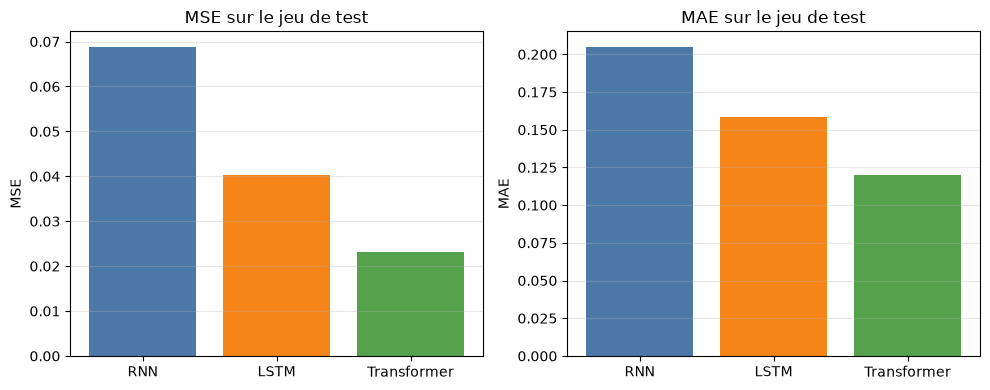

In [6]:
print(f"{'Modèle':<14} {'MSE test':>12} {'MAE test':>12}")
print('-' * 40)
for name, scores in results.items():
    print(f"{name:<14} {scores['MSE']:>12.5f} {scores['MAE']:>12.5f}")

best_model_name = min(results, key=lambda name: results[name]['MSE'])
print(f'\nMeilleur MSE test dans cette exécution : {best_model_name}')

names = list(results)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, metric in zip(axes, ('MSE', 'MAE')):
    axis.bar(names, [results[name][metric] for name in names], color=['#4C78A8', '#F58518', '#54A24B'])
    axis.set_title(f'{metric} sur le jeu de test')
    axis.set_ylabel(metric)
    axis.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Visualisation d'une prédiction

On choisit un exemple du jeu de test. Les observations d'entrée sont affichées aux temps 0 à 11 ; la cible et la prédiction sont placées au temps 12, c'est-à-dire au pas suivant.


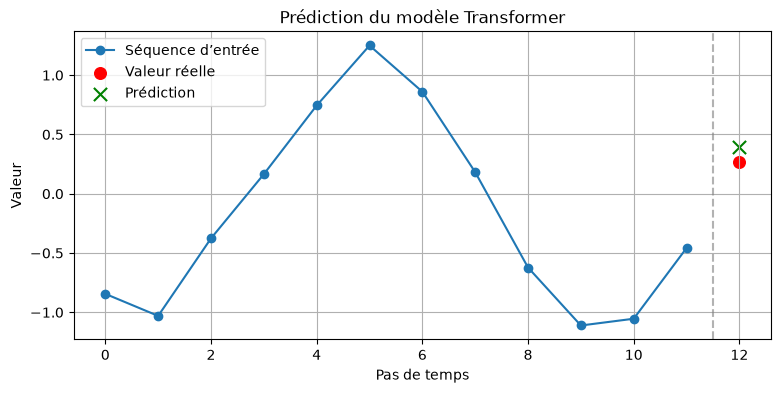

Valeur réelle : 0.2687
Valeur prédite : 0.3980


In [7]:
model = trained_models[best_model_name]
model.eval()
sample_index = int(test_indices[0])
sequence = X[sample_index]
actual_value = float(y[sample_index, 0])

with torch.no_grad():
    sample_tensor = torch.from_numpy(sequence).unsqueeze(0).to(device)
    predicted_value = float(model(sample_tensor).cpu().item())

future_time = len(sequence)
plt.figure(figsize=(9, 4))
plt.plot(np.arange(len(sequence)), sequence[:, 0], marker='o', label='Séquence d’entrée')
plt.scatter([future_time], [actual_value], color='red', s=70, label='Valeur réelle')
plt.scatter([future_time], [predicted_value], color='green', marker='x', s=90, label='Prédiction')
plt.axvline(future_time - 0.5, color='gray', linestyle='--', alpha=0.6)
plt.xlabel('Pas de temps')
plt.ylabel('Valeur')
plt.title(f'Prédiction du modèle {best_model_name}')
plt.legend()
plt.grid(True)
plt.show()
print(f'Valeur réelle : {actual_value:.4f}')
print(f'Valeur prédite : {predicted_value:.4f}')


## Conclusion à rédiger

Complète ces points après avoir exécuté le notebook :

1. Quel modèle obtient la plus petite MSE et la plus petite MAE sur le test ?
2. Quelle est la différence entre les résultats RNN, LSTM et Transformer ?
3. La prédiction illustrée est-elle proche de la valeur réelle ?
4. Pourquoi faut-il réserver un jeu de test qui n'a pas servi à l'entraînement ?

**À retenir :** sur ce petit problème synthétique, il n'y a pas de garantie que le Transformer gagne. Les résultats dépendent du jeu de données, du bruit, des hyperparamètres et de l'aléa d'entraînement. Une comparaison sérieuse devrait répéter les expériences avec plusieurs graines.
